# 01. Четыре признака: как устроен классификатор и где он ошибается

Основная модель — **логистическая регрессия `logistic_basic`**.
ExtraTrees на тех же четырёх признаках оставлен для сравнения.
Здесь загружаются существующие результаты: обучение не запускается.

Графики и фотографии сохранены в ноутбуке. Для повторного расчёта графиков
достаточно файлов репозитория; оригинальные фотографии нужны только для галереи.
Порядок работы и установка — в [README.md](README.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'focus_classifier' / 'features.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from fast_focus_4.workbench import (
    HERE, ART, PICTURES, BASIC, MODEL_IDS, load_data, baseline_table,
    load_model, predict_files, benchmark, run_ablations, photo_grid,
)
from focus_classifier.report import decision_metrics, probability_metrics
from research.evaluate_calibration import calibration_bins
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
table = load_data()
valid = table.loc[table.y >= 0].copy()
print(f'Корень: {ROOT}')
print(f'Всего {len(table)}; для обучения/метрик {len(valid)}; '
      f'ok={int(valid.y.sum())}, not_ok={int((valid.y == 0).sum())}; '
      f'пациентов={valid.patient_id.nunique()}')

Корень: C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капилляроскоп\резкость
Всего 1000; для обучения/метрик 565; ok=62, not_ok=503; пациентов=93


## Что означает метка

`ok=1`: границы мелких и крупных сосудов основной сети различимы по полю кадра.
Размытый глубокий фон допустим, если основная сеть чёткая.
`not_ok=0`: кадр этим требованиям не соответствует.
Неуверенность и расхождения **не превращаем в плохие кадры**: 435 изображений
исключены из бинарной оценки. У оставшихся 565 кадров согласованы историческая
и перекрёстная оценки; согласие не гарантирует истинность разметки.

Все оценки ниже — OOF: пациент фотографии отсутствовал при обучении соответствующей
внешней модели. Это пять частей по пациентам, с тремя внутренними частями
для калибровки и порогов. Выбор между моделями остаётся исследовательским.

In [2]:
display(pd.crosstab(valid['fold'], valid['y']).rename(columns={0:'not_ok', 1:'ok'}))
report = json.loads((ART / 'metrics.json').read_text(encoding='utf-8'))
display(baseline_table().round(4))

y,not_ok,ok
fold,,
0,109,15
1,104,15
2,108,7
3,87,10
4,95,15


,auroc,auroc_ci95,ap,ece_ok_10_raw,ece_ok_10,precision_ok,recall_ok,tp,fp,fn,tn,png_to_decision_p50_ms
model,,,,,,,,,,,,
logistic_basic,0.8800,"[0.834915789854549, 0.9238608517785182]",0.4679,0.2108,0.0406,0.3333,0.8548,53,106,9,397,63.4569
trees_basic,0.8746,"[0.8158063490864386, 0.9245067914870763]",0.5029,0.1630,0.0195,0.3740,0.7419,46,77,16,426,73.1965


## Какие именно четыре признака

Вход — 8-битный кадр **1024×768**, перевод в серый и деление на 255.
`a` — нормированное изображение, `s` — GaussianBlur с σ=1 пиксель.

| Признак | Расчёт | Ограничение |
| --- | --- | --- |
| `laplacian_raw` | Дисперсия Laplacian(a), ядро 1 | Шум тоже увеличивает значение |
| `laplacian_smooth` | Дисперсия Laplacian(s), ядро 1 | Сглаживание ослабляет мелкие детали |
| `tenengrad_smooth` | Среднее SobelX(s)² + SobelY(s)², ядра 3×3 | Зависит от контраста и количества границ |
| `local_tenengrad_p75` | p75 средних энергий градиента по сетке 4×4 | Чёткая часть может скрыть размытие остального поля |

Сетка нужна только для одного статистического признака: отдельные классификаторы
частей изображения не обучаются. Реализация общая с рабочим клиентом:
`focus_classifier/features.py`, режим `basic_only=True`.

,feature,auroc_higher_is_better
0,laplacian_raw,0.4124
1,laplacian_smooth,0.4785
2,tenengrad_smooth,0.6649
3,local_tenengrad_p75,0.6899


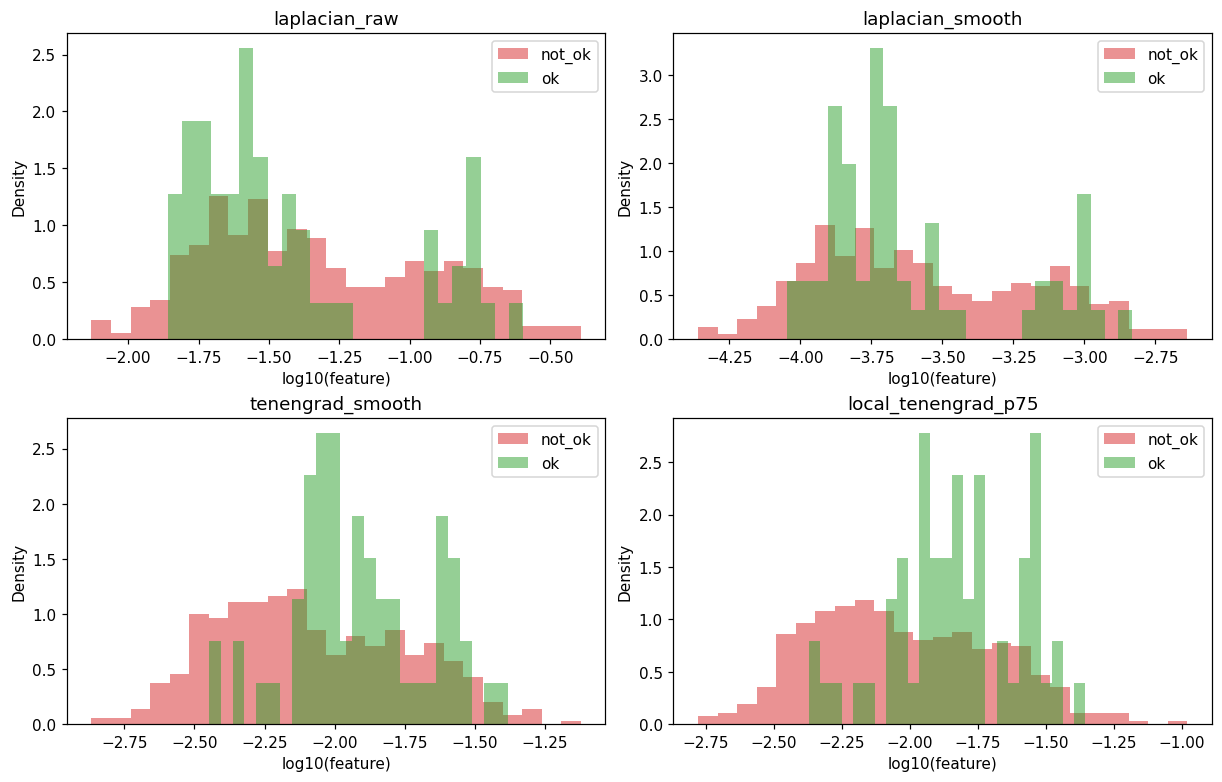

In [3]:
from sklearn.metrics import roc_auc_score
display(pd.DataFrame([dict(feature=f, auroc_higher_is_better=roc_auc_score(valid.y, valid[f]))
                      for f in BASIC]).round(4))
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout='constrained')
for ax, feature in zip(axes.flat, BASIC):
    for label, color in [(0, 'tab:red'), (1, 'tab:green')]:
        ax.hist(np.log10(np.maximum(valid.loc[valid.y == label, feature], 1e-10)),
                bins=25, density=True, alpha=.5, label=['not_ok', 'ok'][label], color=color)
    ax.set(title=feature, xlabel='log10(feature)', ylabel='Density')
    ax.legend()
plt.show()

Эти AUROC относятся к **сырым значениям на 565 согласованных кадрах**:
направление «больше = лучше» задано заранее. Они не равны AUROC обученной
одномерной модели и не сравниваются напрямую со старой оценкой на 790 метках.

## Как четыре числа становятся вероятностью

Для LR: `log10(max(feature, 1e-10))` → StandardScaler → LogisticRegression
(`C=1`, `class_weight='balanced'`) → sigmoid-калибровка исходной вероятности.
Масштабы обучаются внутри соответствующей обучающей части.
Итоговый рабочий экземпляр обучен на всех 565 кадрах; его коэффициенты ниже
служат объяснением модели, а не независимой проверкой качества.

In [4]:
bundle = load_model('logistic_basic')
pipeline = bundle['model']
coefficients = pd.DataFrame({'feature': BASIC,
                             'weight_after_log_and_standardization': pipeline[-1].coef_[0]})
display(coefficients)
print('Пороги итоговой модели:', bundle['thresholds'])
print('Sigmoid-калибровка: slope=', bundle['calibrator'].coef_[0,0],
      'intercept=', bundle['calibrator'].intercept_[0])

,feature,weight_after_log_and_standardization
0,laplacian_raw,-2.804306
1,laplacian_smooth,-0.125858
2,tenengrad_smooth,1.790131
3,local_tenengrad_p75,1.688487


Пороги итоговой модели: {'balanced': 0.09036855151405984, 'precise': 2.0}
Sigmoid-калибровка: slope= 0.7638309089203911 intercept= -2.015607260672232


Коэффициенты работают совместно: признаки коррелируют, поэтому знак коэффициента
не доказывает, что конкретный физический эффект улучшает или ухудшает изображение.

## Ранжирование и решения

AUROC — качество порядка изображений, AP — поиск редких `ok`.
Precision — доля хороших среди принятых, recall — доля сохранённых хороших.
На этом наборе всегда отклонять всё даёт 89% accuracy и нулевой recall,
поэтому одной accuracy недостаточно.

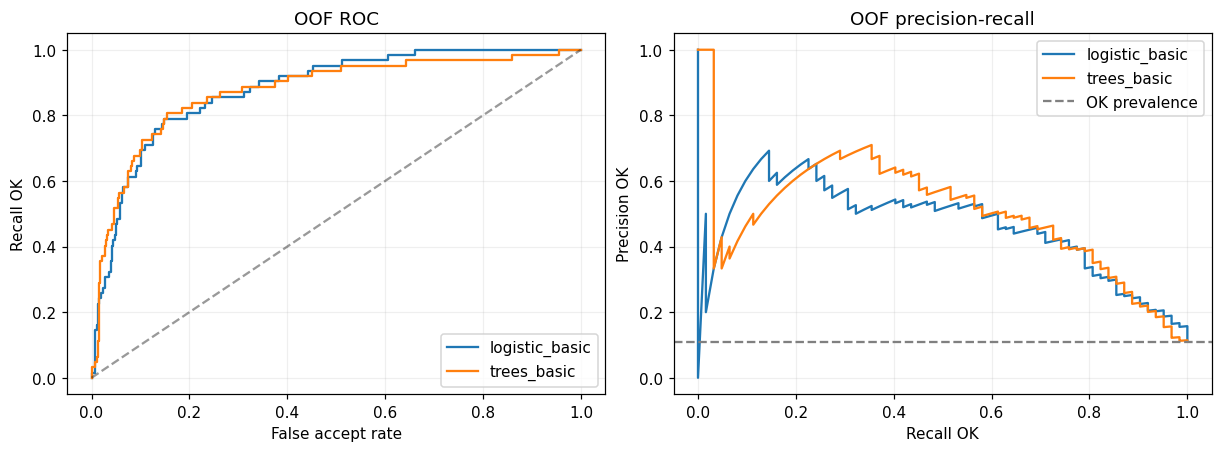

,model,tp,fp,fn,tn,accepted,accuracy,balanced_accuracy,precision_ok,recall_ok,false_accept_rate,coverage
0,logistic_basic,53,106,9,397,159,0.7965,0.8221,0.3333,0.8548,0.2107,0.2814
1,trees_basic,46,77,16,426,123,0.8354,0.7944,0.3740,0.7419,0.1531,0.2177


In [5]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
for model in MODEL_IDS:
    p = valid[f'{model}__p'].to_numpy()
    fpr, tpr, _ = roc_curve(valid.y, p)
    precision, recall, _ = precision_recall_curve(valid.y, p)
    axes[0].plot(fpr, tpr, label=model)
    axes[1].plot(recall, precision, label=model)
axes[0].plot([0,1], [0,1], 'k--', alpha=.4)
axes[1].axhline(valid.y.mean(), ls='--', color='gray', label='OK prevalence')
axes[0].set(xlabel='False accept rate', ylabel='Recall OK', title='OOF ROC')
axes[1].set(xlabel='Recall OK', ylabel='Precision OK', title='OOF precision-recall')
for ax in axes:
    ax.legend(); ax.grid(alpha=.2)
plt.show()
display(pd.DataFrame([dict(model=m, **decision_metrics(valid.y.to_numpy(), valid[f'{m}__p'].to_numpy(),
                              valid[f'{m}__balanced'].to_numpy())) for m in MODEL_IDS]).round(4))

В обычном режиме LR принимает **53 хороших и 106 плохих** фотографий,
теряя 9 хороших. Это полезная точка отсчёта для улучшения, но недостаточная
чистота автоматического отбора. Обычный порог максимизирует balanced accuracy
на внутренних данных и не обязан равняться 0,5.

Строгий порог требовал наблюдаемую precision ≥90% минимум на пяти принятых
внутренних кадрах. Обе модели на четырёх признаках такой режим не обеспечили:
служебный порог 2 означает **«автодопуск отключён»**, а не плохое качество кадра.

## ECE: соответствуют ли вероятности частотам

`ECE_ok = Σ (n_bin/N) · |mean(P(ok)) − fraction(ok)|`.
Ниже — десять равных интервалов, исходные и откалиброванные вероятности.
Для сравнения выводим также top-label ECE: уверенность в выбранном при 0,5
классе против факта правильности этого класса. Это другая величина, её
нельзя незаметно смешивать с ECE вероятности `ok`.

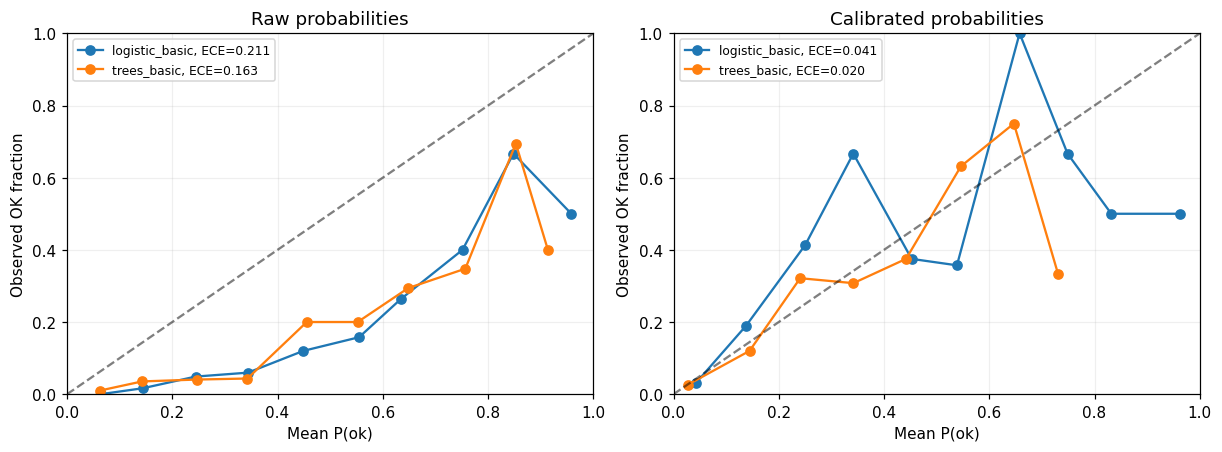

,model,variant,ECE_ok_5,ECE_ok_10,ECE_ok_15,ECE_top_10,Brier
0,logistic_basic,raw,0.2108,0.2108,0.2108,0.0910,0.1303
1,logistic_basic,p,0.0273,0.0406,0.0382,0.0302,0.0750
2,trees_basic,raw,0.1630,0.1630,0.1630,0.0565,0.1059
3,trees_basic,p,0.0083,0.0195,0.0264,0.0195,0.0689


,model,variant,left,right,count,mean_probability,observed_frequency
10,logistic_basic,p,0.0,0.1,429,0.042046,0.030303
11,logistic_basic,p,0.1,0.2,58,0.137807,0.189655
12,logistic_basic,p,0.2,0.3,29,0.250413,0.413793
13,logistic_basic,p,0.3,0.4,6,0.341623,0.666667
14,logistic_basic,p,0.4,0.5,8,0.452363,0.375000
15,logistic_basic,p,0.5,0.6,14,0.538573,0.357143
16,logistic_basic,p,0.6,0.7,4,0.657634,1.000000
17,logistic_basic,p,0.7,0.8,9,0.748714,0.666667
18,logistic_basic,p,0.8,0.9,6,0.831863,0.500000
19,logistic_basic,p,0.9,1.0,2,0.963038,0.500000


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
ece_rows, bin_rows = [], []
y = valid.y.to_numpy()
for model in MODEL_IDS:
    for j, suffix in enumerate(['raw', 'p']):
        p = valid[f'{model}__{suffix}'].to_numpy()
        metrics = probability_metrics(y, p)
        ece, bins = calibration_bins(p, y, 10)
        occupied = [b for b in bins if b['count']]
        axes[j].plot([b['mean_probability'] for b in occupied],
                     [b['observed_frequency'] for b in occupied], 'o-', label=f'{model}, ECE={ece:.3f}')
        ece_rows.append(dict(model=model, variant=suffix,
                             **{f'ECE_ok_{n}': metrics['ece_ok'][str(n)] for n in [5,10,15]},
                             ECE_top_10=metrics['ece_top']['10'], Brier=metrics['brier']))
        bin_rows.extend(dict(model=model, variant=suffix, **b) for b in bins)
for j, ax in enumerate(axes):
    ax.plot([0,1], [0,1], 'k--', alpha=.5)
    ax.set(xlim=(0,1), ylim=(0,1), xlabel='Mean P(ok)', ylabel='Observed OK fraction',
           title=['Raw probabilities', 'Calibrated probabilities'][j])
    ax.legend(fontsize=8); ax.grid(alpha=.2)
plt.show()
display(pd.DataFrame(ece_rows).round(4))
display(pd.DataFrame(bin_rows).query("model == 'logistic_basic' and variant == 'p'"))

У LR ECE_ok(10) снижается примерно с 0,211 до 0,041.
Малый ECE не означает качественный отбор: константный прогноз частоты класса
тоже может иметь низкий ECE. В редких высоковероятностных интервалах мало
фотографий; смотрите числа кадров в таблице, Brier, PR и реальные ошибки.

## Фотографии: правильные решения и уверенные ошибки

Автоматически выбираем по два примера TP, FP, FN и TN по OOF-оценкам LR.
Это иллюстрации, выбранные по результату проверки; они не являются отдельным тестом.
Исходный масштаб фотографии важен: в превью мелкие границы могут потеряться.

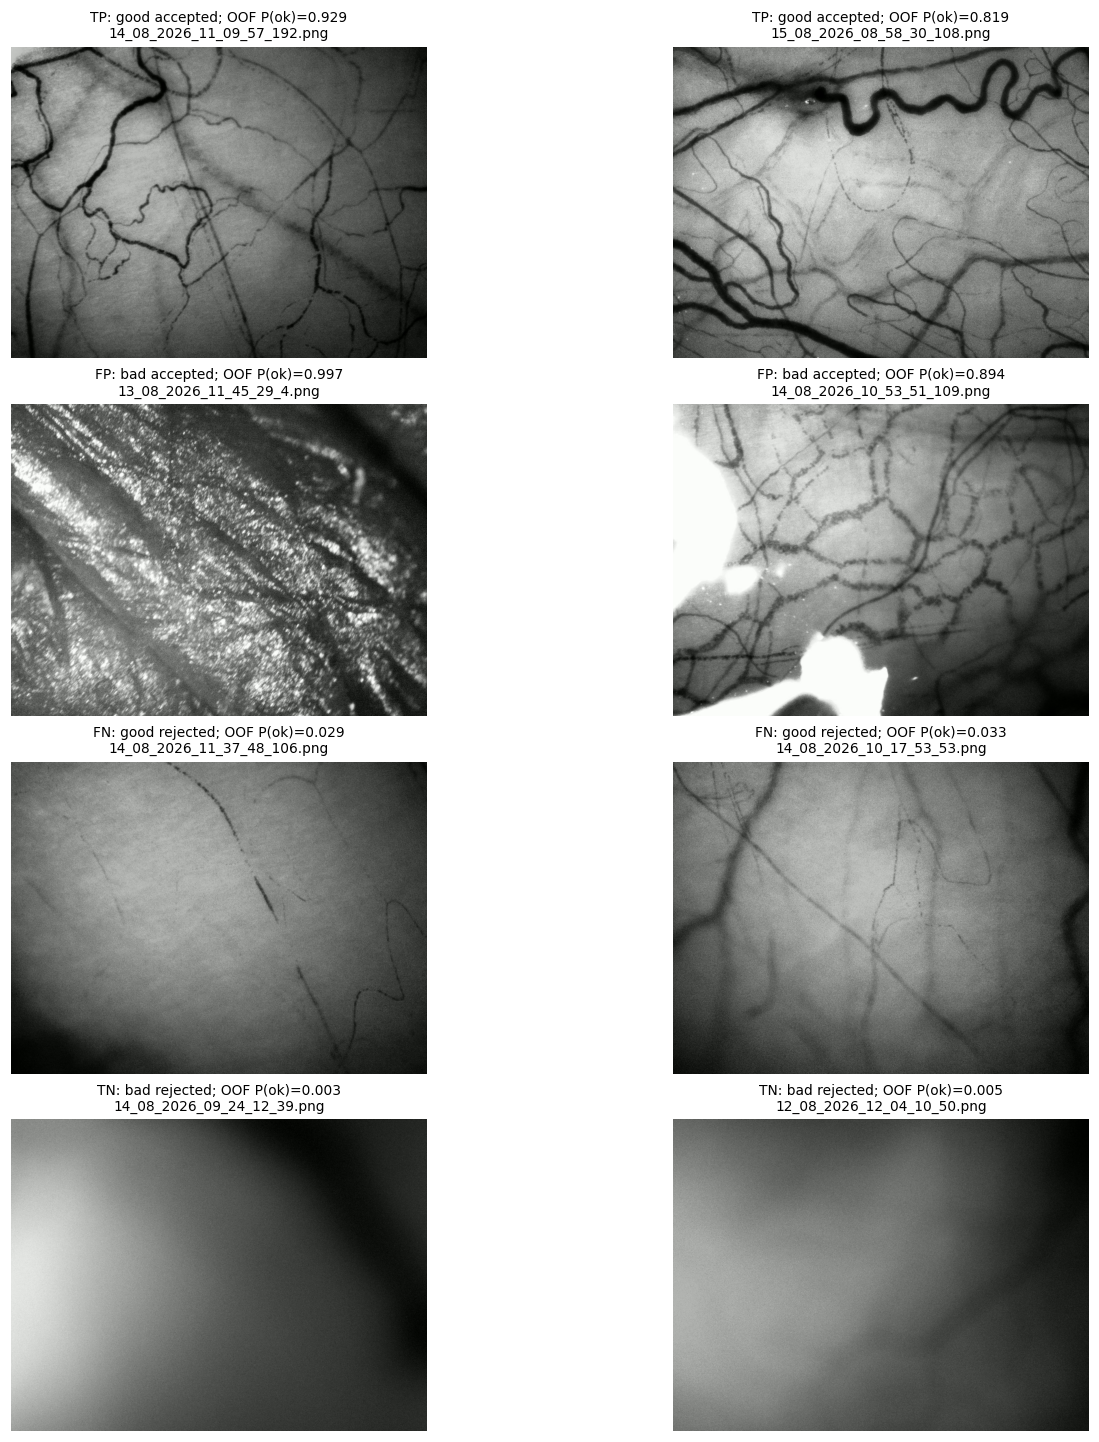

,file,patient_id,y,logistic_basic__p,laplacian_raw,laplacian_smooth,tenengrad_smooth,local_tenengrad_p75,review_comment
539,13_08_2026_11_45_29_4.png,14425,0,0.996946,0.040722,0.000804,0.075710,0.104717,
808,14_08_2026_10_53_51_109.png,14442,0,0.893975,0.015387,0.000127,0.013814,0.018148,Крупные засветки слева и снизу закрывают сосуд...
861,14_08_2026_08_01_03_60.png,14434,0,0.839829,0.027071,0.000179,0.017656,0.024010,
784,12_08_2026_15_21_23_11.png,3807,0,0.824428,0.020191,0.000164,0.015084,0.019147,Большая засветка закрывает значительную часть ...
156,13_08_2026_10_42_19_37.png,14422,0,0.739708,0.015692,0.000105,0.010041,0.014554,
810,13_08_2026_10_42_19_84.png,14422,0,0.729754,0.010785,0.000084,0.008120,0.010767,Резкость неоднородна: слева тонкие ветви разли...
155,14_08_2026_10_18_39_25.png,14440,0,0.714142,0.012527,0.000078,0.007911,0.012061,
885,13_08_2026_14_32_33_108.png,14431,0,0.581871,0.008242,0.000066,0.005874,0.006261,
410,14_08_2026_11_38_25_14.png,14446,0,0.570553,0.010592,0.000082,0.006795,0.008614,
379,13_08_2026_12_29_30_14.png,14428,0,0.565081,0.033608,0.000200,0.015237,0.018872,


In [7]:
fig = photo_grid(table, per_case=2)
plt.show()
mistakes = valid.loc[((valid.y == 0) & (valid.logistic_basic__p >= valid.logistic_basic__balanced)) |
                     ((valid.y == 1) & (valid.logistic_basic__p < valid.logistic_basic__balanced))]
display(mistakes.sort_values('logistic_basic__p', ascending=False)[
    ['file','patient_id','y','logistic_basic__p', *BASIC, 'review_comment']].head(12))

## Что улучшать и как проверять

Сначала отделить вклад признаков от выбора порога и ошибок разметки.
Во втором ноутбуке воспроизводим LR-4 и исключаем по одному признаку,
сохраняя одинаковые внешние части по пациентам. В третьем — оценка своих
файлов и измерение времени. Подробные ограничения и план — в `README.md`.